In [1]:
# Interpretable Postpartum Anxiety Symptom Screening Using Confidence-Gated Hybrid Machine Learning

# Task 1: Import libraries
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from scipy import stats
from sklearn.ensemble import (ExtraTreesClassifier, HistGradientBoostingClassifier,
                              RandomForestClassifier)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             matthews_corrcoef, recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_predict, cross_validate)
from sklearn.naive_bayes import CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.svm import SVC

In [2]:
# Task 2: Settings (all fixed before running the experiment)
DATA_FILE = "post natal data.csv"
RESULTS_FOLDER = Path("results_cgth")
RESULTS_FOLDER.mkdir(exist_ok=True)

TARGET = "Feeling anxious"
SEED = 42
DELTA = 0.2                                      # confidence gate of the proposed hybrid
DELTA_GRID = np.round(np.arange(0, 0.55, 0.05), 2)
NON_INFERIORITY_MARGIN = 0.03                    # largest acceptable loss of balanced accuracy vs RF

versions = (f"numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__} | "
            f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")
(RESULTS_FOLDER / "library_versions.txt").write_text(versions)
print(versions)

numpy 2.4.6 | pandas 3.1.0 | scipy 1.17.1 | scikit-learn 1.9.1 | matplotlib 3.11.2


In [3]:
# Task 3: Load the dataset (the CSV file is only read, never changed)
raw = pd.read_csv(DATA_FILE)
print("Rows and columns:", raw.shape)
raw.head()

Rows and columns: (1503, 11)


,Timestamp,Age,Feeling sad or Tearful,Irritable towards baby & partner,Trouble sleeping at night,Problems concentrating or making decision,Overeating or loss of appetite,Feeling anxious,Feeling of guilt,Problems of bonding with baby,Suicide attempt
0,6/14/2022 20:02,35-40,Yes,Yes,Two or more days a week,Yes,Yes,Yes,No,Yes,Yes
1,6/14/2022 20:03,40-45,Yes,No,No,Yes,Yes,No,Yes,Yes,No
2,6/14/2022 20:04,35-40,Yes,No,Yes,Yes,Yes,Yes,No,Sometimes,No
3,6/14/2022 20:05,35-40,Yes,Yes,Yes,Yes,No,Yes,Maybe,No,No
4,6/14/2022 20:06,40-45,Yes,No,Two or more days a week,Yes,No,Yes,No,Yes,No


In [4]:
# Task 4: Data audit - how many rows are exact duplicates?
answers = raw.drop(columns="Timestamp")
unique_rows = answers.drop_duplicates().reset_index(drop=True)

print("Total rows:", len(answers))
print("Duplicate rows:", answers.duplicated().sum())
print("Unique rows:", len(unique_rows))

Total rows: 1503
Duplicate rows: 1177
Unique rows: 326


In [5]:
# Task 5: Clean data - unique rows only, features (X) and target (y)
def split_features_target(data):
    X = data.drop(columns=TARGET).astype(object)
    y = (data[TARGET] == "Yes").astype(int).to_numpy()
    return X, y


X, y = split_features_target(unique_rows)
print("Positive rate (Feeling anxious = Yes):", round(y.mean(), 3))

Positive rate (Feeling anxious = Yes): 0.58


In [6]:
# Task 6: Base models - missing values and encoding are learned inside each training fold
def preprocessing():
    return make_pipeline(SimpleImputer(strategy="most_frequent"),
                         OneHotEncoder(handle_unknown="ignore"))


def logistic_regression():
    return make_pipeline(preprocessing(), LogisticRegression(max_iter=1000))


def random_forest():
    return make_pipeline(preprocessing(),
                         RandomForestClassifier(n_estimators=300, max_depth=4, random_state=SEED))

In [7]:
# Task 7: Proposed method - Confidence-Gated Transparent Hybrid (CGTH)
# Step 1: the transparent model (Logistic Regression) decides every case it is confident about.
# Step 2: only uncertain cases (probability close to 0.5) are passed to the Random Forest.
def confidence_gated_hybrid(lr_prob, rf_prob, delta):
    decided_by_lr = np.abs(lr_prob - 0.5) >= delta
    final_prob = np.where(decided_by_lr, lr_prob, rf_prob)
    return final_prob, decided_by_lr


# Comparison hybrid: the usual soft-voting average of the same two models
def soft_voting(lr_prob, rf_prob):
    return (lr_prob + rf_prob) / 2

In [8]:
# Task 8: Evaluation metrics (decision threshold 0.5)
def decision_metrics(y_true, prob):
    pred = (prob >= 0.5).astype(int)
    return {
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "accuracy": accuracy_score(y_true, pred),
        "sensitivity": recall_score(y_true, pred),
        "specificity": recall_score(y_true, pred, pos_label=0),
        "f1": f1_score(y_true, pred),
        "mcc": matthews_corrcoef(y_true, pred),
        "roc_auc": roc_auc_score(y_true, prob),
    }

In [9]:
# Task 9: Experiment - 5-fold cross-validation repeated 10 times (50 folds)
def run_cv(X, y):
    scores, curve, gate_check = [], [], []
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)

    for fold, (train, test) in enumerate(cv.split(X, y)):
        X_train, X_test = X.iloc[train], X.iloc[test]
        y_train, y_test = y[train], y[test]

        lr_prob = logistic_regression().fit(X_train, y_train).predict_proba(X_test)[:, 1]
        rf_prob = random_forest().fit(X_train, y_train).predict_proba(X_test)[:, 1]
        hybrid_prob, decided_by_lr = confidence_gated_hybrid(lr_prob, rf_prob, DELTA)

        predictions = {
            "Logistic Regression": lr_prob,
            "Random Forest": rf_prob,
            "Soft Voting (LR+RF)": soft_voting(lr_prob, rf_prob),
            "CGTH (proposed)": hybrid_prob,
        }
        for name, prob in predictions.items():
            row = {"fold": fold, "model": name, **decision_metrics(y_test, prob)}
            row["lr_coverage"] = decided_by_lr.mean() if name == "CGTH (proposed)" else np.nan
            scores.append(row)

        for delta in DELTA_GRID:
            prob, decided = confidence_gated_hybrid(lr_prob, rf_prob, delta)
            curve.append({"fold": fold, "delta": delta, "lr_coverage": decided.mean(),
                          "balanced_accuracy": balanced_accuracy_score(y_test, prob >= 0.5)})

        uncertain = ~decided_by_lr
        gate_check.append({
            "fold": fold,
            "LR on confident cases": accuracy_score(y_test[decided_by_lr], lr_prob[decided_by_lr] >= 0.5),
            "LR on uncertain cases": accuracy_score(y_test[uncertain], lr_prob[uncertain] >= 0.5),
            "RF on uncertain cases": accuracy_score(y_test[uncertain], rf_prob[uncertain] >= 0.5),
        })

    return pd.DataFrame(scores), pd.DataFrame(curve), pd.DataFrame(gate_check)


scores, curve, gate_check = run_cv(X, y)
scores.to_csv(RESULTS_FOLDER / "fold_scores.csv", index=False)

In [10]:
# Task 10: Results table - mean with corrected 95% confidence interval
# The Nadeau-Bengio correction widens the interval because CV training sets overlap.
N_TEST = len(y) / 5
N_TRAIN = len(y) - N_TEST


def corrected_se(values):
    return np.sqrt((1 / len(values) + N_TEST / N_TRAIN) * np.var(values, ddof=1))


def mean_with_ci(values):
    margin = stats.t.ppf(0.975, len(values) - 1) * corrected_se(values)
    return f"{values.mean():.3f} [{values.mean() - margin:.3f}, {values.mean() + margin:.3f}]"


metrics = ["balanced_accuracy", "accuracy", "sensitivity", "specificity", "f1", "mcc", "roc_auc"]
results = scores.groupby("model", sort=False)[metrics].agg(mean_with_ci)
results["lr_coverage"] = scores.groupby("model", sort=False)["lr_coverage"].mean().round(3)
results.to_csv(RESULTS_FOLDER / "results_table.csv")
results

,balanced_accuracy,accuracy,sensitivity,specificity,f1,mcc,roc_auc,lr_coverage
model,,,,,,,,
Logistic Regression,"0.730 [0.667, 0.794]","0.745 [0.682, 0.808]","0.821 [0.749, 0.893]","0.639 [0.553, 0.726]","0.788 [0.733, 0.843]","0.473 [0.343, 0.603]","0.800 [0.740, 0.859]",NaN
Random Forest,"0.761 [0.706, 0.816]","0.780 [0.728, 0.833]","0.881 [0.825, 0.937]","0.642 [0.553, 0.730]","0.823 [0.780, 0.866]","0.547 [0.436, 0.657]","0.835 [0.784, 0.886]",NaN
Soft Voting (LR+RF),"0.741 [0.678, 0.804]","0.760 [0.698, 0.822]","0.857 [0.784, 0.930]","0.626 [0.538, 0.713]","0.805 [0.752, 0.858]","0.504 [0.372, 0.636]","0.820 [0.765, 0.874]",NaN
CGTH (proposed),"0.757 [0.700, 0.813]","0.776 [0.722, 0.830]","0.878 [0.820, 0.936]","0.635 [0.547, 0.723]","0.820 [0.775, 0.864]","0.538 [0.423, 0.653]","0.809 [0.751, 0.867]",0.684


In [11]:
# Task 11: Hypothesis tests on balanced accuracy (paired by fold)
# H1: CGTH is non-inferior to Random Forest (loses less than the margin).
# H2: CGTH is better than Logistic Regression.
per_fold = scores.pivot(index="fold", columns="model", values="balanced_accuracy")
k = len(per_fold)

diff_rf = per_fold["CGTH (proposed)"] - per_fold["Random Forest"]
t_rf = (diff_rf.mean() + NON_INFERIORITY_MARGIN) / corrected_se(diff_rf)
p_rf = stats.t.sf(t_rf, df=k - 1)

diff_lr = per_fold["CGTH (proposed)"] - per_fold["Logistic Regression"]
t_lr = diff_lr.mean() / corrected_se(diff_lr)
p_lr = stats.t.sf(t_lr, df=k - 1)

tests = pd.DataFrame({
    "hypothesis": ["H1 CGTH non-inferior to RF", "H2 CGTH better than LR"],
    "mean_difference": [diff_rf.mean(), diff_lr.mean()],
    "t": [t_rf, t_lr],
    "one_sided_p": [p_rf, p_lr],
}).round(4)
tests["supported (p < 0.05)"] = tests["one_sided_p"] < 0.05
tests.to_csv(RESULTS_FOLDER / "hypothesis_tests.csv", index=False)
tests

,hypothesis,mean_difference,t,one_sided_p,supported (p < 0.05)
0,H1 CGTH non-inferior to RF,-0.0046,5.0147,0.0000,True
1,H2 CGTH better than LR,0.0264,1.4243,0.0803,False


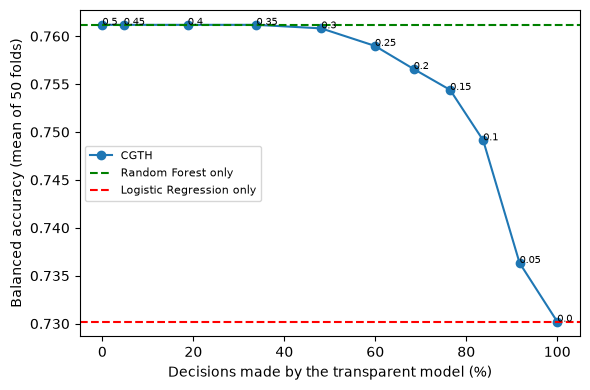

In [12]:
# Task 12: Figure - transparency vs performance for every gate value
mean_curve = curve.groupby("delta")[["lr_coverage", "balanced_accuracy"]].mean()
rf_score = per_fold["Random Forest"].mean()
lr_score = per_fold["Logistic Regression"].mean()

plt.figure(figsize=(6, 4))
plt.plot(mean_curve["lr_coverage"] * 100, mean_curve["balanced_accuracy"], marker="o", label="CGTH")
plt.axhline(rf_score, color="green", linestyle="--", label="Random Forest only")
plt.axhline(lr_score, color="red", linestyle="--", label="Logistic Regression only")
for delta, row in mean_curve.iterrows():
    plt.annotate(f"{delta}", (row["lr_coverage"] * 100, row["balanced_accuracy"]), fontsize=7)
plt.xlabel("Decisions made by the transparent model (%)")
plt.ylabel("Balanced accuracy (mean of 50 folds)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS_FOLDER / "transparency_vs_performance.png", dpi=300)
plt.show()

In [13]:
# Task 13: Why the gate works - accuracy on confident vs uncertain cases
gate_summary = gate_check.drop(columns="fold").mean().round(3).to_frame("mean_accuracy")
gate_summary.to_csv(RESULTS_FOLDER / "gate_check.csv")
gate_summary

,mean_accuracy
LR on confident cases,0.806
LR on uncertain cases,0.606
RF on uncertain cases,0.709


In [14]:
# Task 14: Explanation of the transparent part - Logistic Regression odds ratios
final_lr = logistic_regression().fit(X, y)
feature_names = final_lr[0][-1].get_feature_names_out(X.columns)
coefficients = final_lr[-1].coef_[0]

explanation = pd.DataFrame({"answer": feature_names, "odds_ratio": np.exp(coefficients)})
explanation["effect"] = np.where(coefficients > 0, "raises probability", "lowers probability")
explanation = explanation.reindex(np.argsort(-np.abs(coefficients))).head(10).round(3)
explanation.to_csv(RESULTS_FOLDER / "lr_odds_ratios.csv", index=False)
explanation

,answer,odds_ratio,effect
22,Feeling of guilt_Yes,0.226,lowers probability
21,Feeling of guilt_No,3.163,raises probability
15,Problems concentrating or making decision_Often,1.846,raises probability
9,Irritable towards baby & partner_Sometimes,0.572,lowers probability
27,Suicide attempt_Not interested to say,0.581,lowers probability
4,Age_45-50,1.671,raises probability
19,Overeating or loss of appetite_Yes,0.639,lowers probability
14,Problems concentrating or making decision_No,0.646,lowers probability
10,Irritable towards baby & partner_Yes,1.536,raises probability
17,Overeating or loss of appetite_No,1.449,raises probability


In [15]:
# Task 15: Robustness checks - duplicate leakage and dependence on the guilt item
X_dup, y_dup = split_features_target(answers)
dup_scores, _, _ = run_cv(X_dup, y_dup)
no_guilt_scores, _, _ = run_cv(X.drop(columns="Feeling of guilt"), y)

robustness = pd.DataFrame({
    "unique rows (main result)": scores.groupby("model")["balanced_accuracy"].mean(),
    "duplicates kept (leakage)": dup_scores.groupby("model")["balanced_accuracy"].mean(),
    "guilt item removed": no_guilt_scores.groupby("model")["balanced_accuracy"].mean(),
}).round(3)
robustness.to_csv(RESULTS_FOLDER / "robustness.csv")
robustness

,unique rows (main result),duplicates kept (leakage),guilt item removed
model,,,
CGTH (proposed),0.757,0.843,0.601
Logistic Regression,0.730,0.796,0.601
Random Forest,0.761,0.855,0.602
Soft Voting (LR+RF),0.741,0.813,0.601


In [16]:
# Task 16: Training-only probabilities for every fold (used by Tasks 17 and 18)
# Inner cross-validation on the training part gives honest probabilities for choosing
# the gate value and the screening threshold, without ever looking at the test fold.
def inner_probabilities(X_train, y_train, seed):
    inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    lr_prob = cross_val_predict(logistic_regression(), X_train, y_train, cv=inner,
                                method="predict_proba")[:, 1]
    rf_prob = cross_val_predict(random_forest(), X_train, y_train, cv=inner,
                                method="predict_proba")[:, 1]
    return lr_prob, rf_prob


folds = []
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
for fold, (train, test) in enumerate(cv.split(X, y)):
    X_train, X_test = X.iloc[train], X.iloc[test]
    y_train, y_test = y[train], y[test]
    train_lr, train_rf = inner_probabilities(X_train, y_train, seed=fold)
    folds.append({
        "y_train": y_train, "train_lr": train_lr, "train_rf": train_rf,
        "y_test": y_test,
        "test_lr": logistic_regression().fit(X_train, y_train).predict_proba(X_test)[:, 1],
        "test_rf": random_forest().fit(X_train, y_train).predict_proba(X_test)[:, 1],
    })

In [17]:
# Task 17: Stricter CGTH - gate value δ chosen inside each training fold
# Rule: the smallest δ (most decisions by LR) whose training balanced accuracy is
# within 0.01 of the best δ. This removes the concern that δ = 0.2 was picked by hand.
def choose_delta(y_train, train_lr, train_rf):
    scores = {}
    for delta in DELTA_GRID:
        prob, _ = confidence_gated_hybrid(train_lr, train_rf, delta)
        scores[delta] = balanced_accuracy_score(y_train, prob >= 0.5)
    best = max(scores.values())
    return min(delta for delta, score in scores.items() if score >= best - 0.01)


rows = []
for f in folds:
    delta = choose_delta(f["y_train"], f["train_lr"], f["train_rf"])
    prob, decided_by_lr = confidence_gated_hybrid(f["test_lr"], f["test_rf"], delta)
    rows.append({"delta": delta, "lr_coverage": decided_by_lr.mean(),
                 **decision_metrics(f["y_test"], prob)})

strict_cgth = pd.DataFrame(rows)
strict_cgth.to_csv(RESULTS_FOLDER / "cgth_delta_in_fold.csv", index=False)
strict_cgth.drop(columns="delta").agg(mean_with_ci)

lr_coverage          0.773 [0.630, 0.916]
balanced_accuracy    0.750 [0.687, 0.813]
accuracy             0.768 [0.706, 0.830]
sensitivity          0.865 [0.797, 0.933]
specificity          0.635 [0.546, 0.724]
f1                   0.812 [0.760, 0.864]
mcc                  0.522 [0.391, 0.653]
roc_auc              0.806 [0.744, 0.868]
dtype: str

In [18]:
# Task 18: Screening operating point - find at least 90% of the anxious answers
# The threshold is chosen on training probabilities only, then applied to the test fold.
TARGET_SENSITIVITY = 0.90


def threshold_for_sensitivity(y_train, train_prob):
    positive_probs = np.sort(train_prob[y_train == 1])
    index = int(np.floor((1 - TARGET_SENSITIVITY) * len(positive_probs)))
    return positive_probs[index]


rows = []
for f in folds:
    delta = choose_delta(f["y_train"], f["train_lr"], f["train_rf"])
    candidates = {
        "Logistic Regression": (f["train_lr"], f["test_lr"]),
        "Random Forest": (f["train_rf"], f["test_rf"]),
        "CGTH (δ in fold)": (confidence_gated_hybrid(f["train_lr"], f["train_rf"], delta)[0],
                             confidence_gated_hybrid(f["test_lr"], f["test_rf"], delta)[0]),
    }
    for name, (train_prob, test_prob) in candidates.items():
        threshold = threshold_for_sensitivity(f["y_train"], train_prob)
        pred = test_prob >= threshold
        rows.append({"model": name, "threshold": threshold,
                     "sensitivity": recall_score(f["y_test"], pred),
                     "specificity": recall_score(f["y_test"], pred, pos_label=0),
                     "balanced_accuracy": balanced_accuracy_score(f["y_test"], pred)})

screening = pd.DataFrame(rows)
screening.to_csv(RESULTS_FOLDER / "screening_90_sensitivity.csv", index=False)
screening.groupby("model", sort=False)[["threshold", "sensitivity", "specificity",
                                        "balanced_accuracy"]].agg(mean_with_ci)

,threshold,sensitivity,specificity,balanced_accuracy
model,,,,
Logistic Regression,"0.342 [0.301, 0.384]","0.902 [0.837, 0.967]","0.496 [0.415, 0.577]","0.699 [0.652, 0.745]"
Random Forest,"0.434 [0.390, 0.478]","0.897 [0.834, 0.961]","0.558 [0.455, 0.661]","0.728 [0.681, 0.775]"
CGTH (δ in fold),"0.362 [0.305, 0.419]","0.897 [0.834, 0.961]","0.509 [0.409, 0.608]","0.703 [0.653, 0.753]"


In [19]:
# Task 19: Hypothesis test for the stricter CGTH (δ chosen inside each training fold)
strict_per_fold = strict_cgth["balanced_accuracy"].to_numpy()

strict_diff_rf = strict_per_fold - per_fold["Random Forest"].to_numpy()
strict_t_rf = (strict_diff_rf.mean() + NON_INFERIORITY_MARGIN) / corrected_se(strict_diff_rf)

strict_diff_lr = strict_per_fold - per_fold["Logistic Regression"].to_numpy()
strict_t_lr = strict_diff_lr.mean() / corrected_se(strict_diff_lr)

strict_tests = pd.DataFrame({
    "hypothesis": ["Strict CGTH non-inferior to RF", "Strict CGTH better than LR"],
    "mean_difference": [strict_diff_rf.mean(), strict_diff_lr.mean()],
    "t": [strict_t_rf, strict_t_lr],
    "one_sided_p": [stats.t.sf(strict_t_rf, df=k - 1), stats.t.sf(strict_t_lr, df=k - 1)],
}).round(4)
strict_tests["supported (p < 0.05)"] = strict_tests["one_sided_p"] < 0.05
strict_tests.to_csv(RESULTS_FOLDER / "strict_hypothesis_tests.csv", index=False)
strict_tests

,hypothesis,mean_difference,t,one_sided_p,supported (p < 0.05)
0,Strict CGTH non-inferior to RF,-0.0112,1.582,0.060,False
1,Strict CGTH better than LR,0.0197,1.154,0.127,False


In [20]:
# Task 20: Fairness check - CGTH results for each age band (the only demographic variable)
prediction_rows = []
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
for fold, (f, (_, test)) in enumerate(zip(folds, cv.split(X, y))):
    prob, decided_by_lr = confidence_gated_hybrid(f["test_lr"], f["test_rf"], DELTA)
    prediction_rows.append(pd.DataFrame({
        "repeat": fold // 5,
        "age": X["Age"].iloc[test].to_numpy(),
        "y": f["y_test"],
        "pred": (prob >= 0.5).astype(int),
        "decided_by_lr": decided_by_lr,
    }))
age_predictions = pd.concat(prediction_rows)

rows = []
for age, group in age_predictions.groupby("age"):
    per_repeat = [balanced_accuracy_score(part["y"], part["pred"])
                  for _, part in group.groupby("repeat")]
    rows.append({
        "age_band": age,
        "unique_rows": len(group) // 10,
        "positive_rate": group["y"].mean(),
        "balanced_accuracy": np.mean(per_repeat),
        "lowest_repeat": min(per_repeat),
        "highest_repeat": max(per_repeat),
        "sensitivity": recall_score(group["y"], group["pred"]),
        "specificity": recall_score(group["y"], group["pred"], pos_label=0),
        "lr_coverage": group["decided_by_lr"].mean(),
    })

age_results = pd.DataFrame(rows).round(3)
age_results.to_csv(RESULTS_FOLDER / "results_by_age_band.csv", index=False)
age_results

,age_band,unique_rows,positive_rate,balanced_accuracy,lowest_repeat,highest_repeat,sensitivity,specificity,lr_coverage
0,25-30,49,0.469,0.664,0.593,0.702,0.748,0.581,0.624
1,30-35,71,0.549,0.824,0.815,0.847,0.967,0.681,0.601
2,35-40,76,0.605,0.760,0.746,0.763,0.826,0.693,0.774
3,40-45,73,0.548,0.755,0.741,0.783,0.878,0.633,0.656
4,45-50,57,0.719,0.726,0.713,0.745,0.927,0.525,0.756


In [21]:
# Task 21: Overfitting check - training vs testing results on the same 50 folds
rows = []
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
for train, test in cv.split(X, y):
    lr_model = logistic_regression().fit(X.iloc[train], y[train])
    rf_model = random_forest().fit(X.iloc[train], y[train])
    for part, index in [("train", train), ("test", test)]:
        lr_prob = lr_model.predict_proba(X.iloc[index])[:, 1]
        rf_prob = rf_model.predict_proba(X.iloc[index])[:, 1]
        predictions = {
            "Logistic Regression": lr_prob,
            "Random Forest": rf_prob,
            "Soft Voting (LR+RF)": soft_voting(lr_prob, rf_prob),
            "CGTH (proposed)": confidence_gated_hybrid(lr_prob, rf_prob, DELTA)[0],
        }
        for name, prob in predictions.items():
            rows.append({"model": name, "part": part,
                         "balanced_accuracy": balanced_accuracy_score(y[index], prob >= 0.5),
                         "roc_auc": roc_auc_score(y[index], prob)})

train_test = pd.DataFrame(rows).groupby(["model", "part"], sort=False).mean().unstack()
train_test.columns = [f"{metric}_{part}" for metric, part in train_test.columns]
train_test["balanced_accuracy_gap"] = train_test["balanced_accuracy_train"] - train_test["balanced_accuracy_test"]
train_test["roc_auc_gap"] = train_test["roc_auc_train"] - train_test["roc_auc_test"]
train_test = train_test.round(3)
train_test.to_csv(RESULTS_FOLDER / "train_vs_test.csv")
train_test

,balanced_accuracy_train,balanced_accuracy_test,roc_auc_train,roc_auc_test,balanced_accuracy_gap,roc_auc_gap
model,,,,,,
Logistic Regression,0.776,0.730,0.859,0.800,0.045,0.059
Random Forest,0.796,0.761,0.934,0.835,0.035,0.099
Soft Voting (LR+RF),0.791,0.741,0.896,0.820,0.050,0.076
CGTH (proposed),0.792,0.757,0.881,0.809,0.036,0.071


In [22]:
# Task 22: Performance ceiling - other model types, tuned inside each training fold
# 5-fold CV repeated 3 times (15 folds) with a 3-fold inner grid search.
def one_hot_model(classifier):
    return make_pipeline(preprocessing(), classifier)


def ordinal_model(classifier):
    return make_pipeline(SimpleImputer(strategy="most_frequent"), OrdinalEncoder(), classifier)


inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=1)


def tuned(model, grid):
    return GridSearchCV(model, grid, cv=inner_cv, scoring="balanced_accuracy")


other_models = {
    "Logistic Regression (tuned)": tuned(
        one_hot_model(LogisticRegression(max_iter=2000)),
        {"logisticregression__C": [0.1, 0.3, 1, 3, 10]}),
    "Random Forest (tuned)": tuned(
        one_hot_model(RandomForestClassifier(n_estimators=300, random_state=SEED)),
        {"randomforestclassifier__max_depth": [3, 5, 8, None],
         "randomforestclassifier__min_samples_leaf": [1, 3, 5]}),
    "Extra Trees (tuned)": tuned(
        one_hot_model(ExtraTreesClassifier(n_estimators=300, random_state=SEED)),
        {"extratreesclassifier__max_depth": [5, 8, None],
         "extratreesclassifier__min_samples_leaf": [1, 3]}),
    "Gradient Boosting (tuned)": tuned(
        ordinal_model(HistGradientBoostingClassifier(categorical_features=[True] * 9, random_state=SEED)),
        {"histgradientboostingclassifier__learning_rate": [0.03, 0.1],
         "histgradientboostingclassifier__max_depth": [2, 3, None]}),
    "SVM (tuned)": tuned(
        one_hot_model(SVC()),
        {"svc__C": [0.3, 1, 3, 10], "svc__gamma": ["scale", 0.03, 0.1]}),
    "k-Nearest Neighbours (tuned)": tuned(
        one_hot_model(KNeighborsClassifier()),
        {"kneighborsclassifier__n_neighbors": [5, 9, 15, 25]}),
    "Categorical Naive Bayes": ordinal_model(CategoricalNB(min_categories=5)),
}

rows = []
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
for name, model in other_models.items():
    result = cross_validate(model, X, y, cv=cv, n_jobs=-1,
                            scoring=["balanced_accuracy", "accuracy", "roc_auc"])
    rows.append({"model": name,
                 "balanced_accuracy": mean_with_ci(result["test_balanced_accuracy"]),
                 "accuracy": mean_with_ci(result["test_accuracy"]),
                 "roc_auc": mean_with_ci(result["test_roc_auc"])})

ceiling = pd.DataFrame(rows).sort_values("balanced_accuracy", ascending=False)
ceiling.to_csv(RESULTS_FOLDER / "performance_ceiling.csv", index=False)
ceiling

,model,balanced_accuracy,accuracy,roc_auc
1,Random Forest (tuned),"0.760 [0.694, 0.826]","0.773 [0.709, 0.837]","0.840 [0.777, 0.904]"
2,Extra Trees (tuned),"0.755 [0.686, 0.824]","0.766 [0.702, 0.829]","0.842 [0.784, 0.900]"
4,SVM (tuned),"0.748 [0.698, 0.798]","0.762 [0.709, 0.815]","0.810 [0.746, 0.874]"
3,Gradient Boosting (tuned),"0.734 [0.663, 0.805]","0.751 [0.685, 0.817]","0.809 [0.740, 0.878]"
6,Categorical Naive Bayes,"0.733 [0.647, 0.819]","0.749 [0.666, 0.832]","0.815 [0.746, 0.883]"
0,Logistic Regression (tuned),"0.732 [0.651, 0.814]","0.749 [0.670, 0.829]","0.805 [0.725, 0.885]"
5,k-Nearest Neighbours (tuned),"0.692 [0.622, 0.761]","0.711 [0.644, 0.778]","0.772 [0.704, 0.840]"


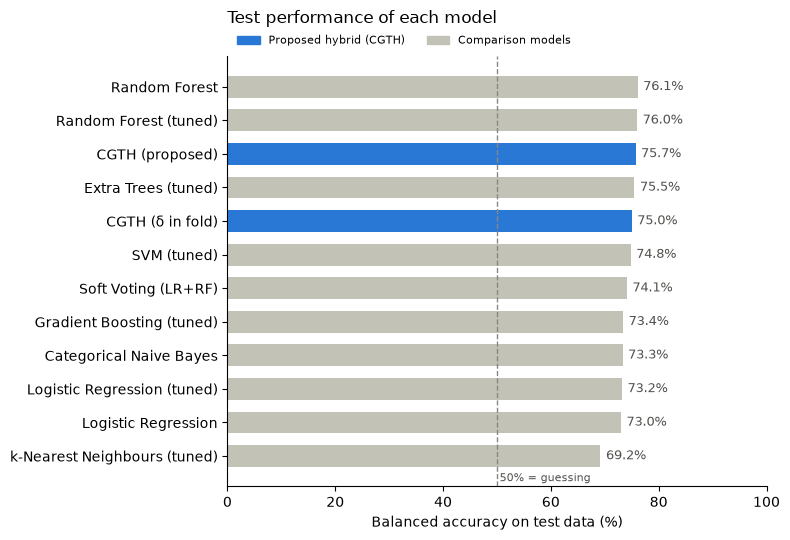

,balanced_accuracy,accuracy,sensitivity,specificity,f1,roc_auc,test_folds
model,,,,,,,
Random Forest,76.1,78.0,88.1,64.2,82.3,83.5,50
Random Forest (tuned),76.0,77.3,NaN,NaN,NaN,84.0,15
CGTH (proposed),75.7,77.6,87.8,63.5,82.0,80.9,50
Extra Trees (tuned),75.5,76.6,NaN,NaN,NaN,84.2,15
CGTH (δ in fold),75.0,76.8,86.5,63.5,81.2,80.6,50
SVM (tuned),74.8,76.2,NaN,NaN,NaN,81.0,15
Soft Voting (LR+RF),74.1,76.0,85.7,62.6,80.5,82.0,50
Gradient Boosting (tuned),73.4,75.1,NaN,NaN,NaN,80.9,15
Categorical Naive Bayes,73.3,74.9,NaN,NaN,NaN,81.5,15


In [23]:
# Task 23: Compare all models - how much result does each model give? (test results in %)
from matplotlib.patches import Patch

metric_names = ["balanced_accuracy", "accuracy", "sensitivity", "specificity", "f1", "roc_auc"]

main_models = scores.groupby("model", sort=False)[metric_names].mean()
main_models.loc["CGTH (δ in fold)"] = strict_cgth[metric_names].mean()
main_models["test_folds"] = 50

# Task 22 stored text such as "0.760 [0.694, 0.826]", so keep only the first number.
tuned_models = ceiling.set_index("model")[["balanced_accuracy", "accuracy", "roc_auc"]]
tuned_models = tuned_models.apply(lambda column: column.str[:5].astype(float))
tuned_models["test_folds"] = 15

comparison = pd.concat([main_models, tuned_models])
comparison[metric_names] = (comparison[metric_names] * 100).round(1)
comparison = comparison.sort_values("balanced_accuracy", ascending=False)
comparison.to_csv(RESULTS_FOLDER / "model_comparison.csv")

chart = comparison.sort_values("balanced_accuracy")
is_cgth = chart.index.str.startswith("CGTH")

plt.figure(figsize=(8, 5.5))
bars = plt.barh(chart.index, chart["balanced_accuracy"], height=0.65,
                color=np.where(is_cgth, "#2a78d6", "#c3c2b7"))
plt.bar_label(bars, fmt="%.1f%%", padding=4, fontsize=9, color="#52514e")
plt.axvline(50, color="#898781", linewidth=1, linestyle="--")
plt.text(50.5, -0.75, "50% = guessing", fontsize=8, color="#52514e")
plt.legend(handles=[Patch(color="#2a78d6", label="Proposed hybrid (CGTH)"),
                    Patch(color="#c3c2b7", label="Comparison models")],
           loc="lower left", bbox_to_anchor=(0, 1), ncol=2, fontsize=8, frameon=False)
plt.xlim(0, 100)
plt.xlabel("Balanced accuracy on test data (%)")
plt.title("Test performance of each model", loc="left", fontsize=12, pad=24)
plt.gca().spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(RESULTS_FOLDER / "model_comparison.png", dpi=300)
plt.show()

comparison